In [1]:
import pandas as pd
import numpy as np

# Инструменты для пайплайна и валидации
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Инструменты предобработки
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Модель классификации
from sklearn.neighbors import KNeighborsClassifier

# Бизнес-метрики качества
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

In [2]:
df = pd.read_csv("insurance.csv")

class_counts = df["smoker"].value_counts(normalize=True) * 100
print(f'Баланс классов:\n0 (Не курят): {class_counts.get("no", 0):.1f}%\n1 (Курят): {class_counts.get("yes", 0):.1f}%')

X = df.drop("smoker", axis=1)
y = df["smoker"].map({"no": 0, "yes": 1})

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(df.columns)


Баланс классов:
0 (Не курят): 79.5%
1 (Курят): 20.5%
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')


In [3]:
numeric_features =['age', 'children', 'bmi']
categorical_features = [ 'sex', 'region']

# Ветка 1: Обработка чисел
numeric_transformer = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]
)
# Ветка 2: Обработка категорий (текста)
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")), 
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]
)
# Объединяем ветки 1 и 2
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)
# Итоговый конвейер: Предобработка -> Модель
clf_pipline = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", KNeighborsClassifier())]
)
# Сетка поиска
param_grid = {
    "classifier__n_neighbors": [3,5,9],
    "classifier__weights": ["uniform", "distance"],
}
# 5-Fold кросс-валидация
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# Сбор всего в GridSearchCV, с проверкой ROC-AUC
grid_search = GridSearchCV(
    estimator=clf_pipline,
    param_grid=param_grid,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1
)
# Обучение
grid_search.fit(X_train, y_train)
# Извлекаем лучшую модель
best_model = grid_search.best_estimator_
print(f'\nЛучшие параметры алгоритма: {grid_search.best_params_}')


Лучшие параметры алгоритма: {'classifier__n_neighbors': 3, 'classifier__weights': 'uniform'}


In [5]:
# Предсказание 0 или 1
y_pred = best_model.predict(X_test)

# Предсказание вероятностей от 0.0 до 1.0 (для ROC-AUC)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("--- Матрица ошибок ---")
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Истинно отрицательные (TN - не курит, модель предсказала не курит) {conf_matrix[0][0]}")
print(f"Ложноположительные (FP - не курит, модель предсказала не курит) {conf_matrix[0][1]}")
print(f"Ложноотрицательные (FN - курит, модель предсказала не курит) {conf_matrix[1][0]}")
print(f"Истинно полжительные (TP - курит, модель предсказала  курит) {conf_matrix[1][1]}")

print("--- Отчет по метрикам ---")
print(classification_report(y_test, y_pred, target_names=["Не курит (0)", "Курит (1)"]))

roc_auc = roc_auc_score(y_test, y_proba)
print(f"Площадь под кривой ROC-AUC: {roc_auc:.4f}")

--- Матрица ошибок ---
Истинно отрицательные (TN - не курит, модель предсказала не курит) 193
Ложноположительные (FP - не курит, модель предсказала не курит) 20
Ложноотрицательные (FN - курит, модель предсказала не курит) 49
Истинно полжительные (TP - курит, модель предсказала  курит) 6
--- Отчет по метрикам ---
              precision    recall  f1-score   support

Не курит (0)       0.80      0.91      0.85       213
   Курит (1)       0.23      0.11      0.15        55

    accuracy                           0.74       268
   macro avg       0.51      0.51      0.50       268
weighted avg       0.68      0.74      0.70       268

Площадь под кривой ROC-AUC: 0.4939


In [6]:
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [7]:
df_reg = df.dropna(subset=["age", "bmi"]).copy()
X_reg = df_reg[["age", "bmi", "children"]]
y_reg = df_reg["charges"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

reg_pipline = Pipeline(
    [("scaler", StandardScaler()), ("knn_reg", KNeighborsRegressor())]
)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
param_dist = {
    "knn_reg__n_neighbors": np.arange(3,30),
    "knn_reg__weights": ["uniform", "distance"],
}
random_search = RandomizedSearchCV(
    estimator=reg_pipline,
    param_distributions=param_dist,
    n_iter=10,
    cv=kf,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_train_r, y_train_r)
best_reg = random_search.best_estimator_
print(f'\nЛучшие параметры алгоритма: {random_search.best_params_}')


Лучшие параметры алгоритма: {'knn_reg__weights': 'uniform', 'knn_reg__n_neighbors': np.int64(27)}


In [8]:
y_pred_r = best_reg.predict(X_test_r)

def smape(y_test, y_pred):
    return 100 * np.mean(
        2 * np.abs(y_pred - y_test) / (np.abs(y_test) + np.abs(y_pred))
    )

mse = mean_squared_error(y_test_r, y_pred_r)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test_r, y_pred_r)
smape_value = smape(y_test_r, y_pred_r)

print("--- Отчет по метрикам регрессии ---")
print(f"MSE (квадратные $) {mse:,.0f}")
print(f"RMSE ($) {rmse:,.2f}")
print(f"MAE (Средняя ошибка) {mae:,.2f}")
print(f"SMAPE (Ошибка в %) {smape_value:,.2f}")

--- Отчет по метрикам регрессии ---
MSE (квадратные $) 135,085,905
RMSE ($) 11,622.65
MAE (Средняя ошибка) 9,114.98
SMAPE (Ошибка в %) 72.60


Text(0, 0.5, 'Кол-во клиентов')

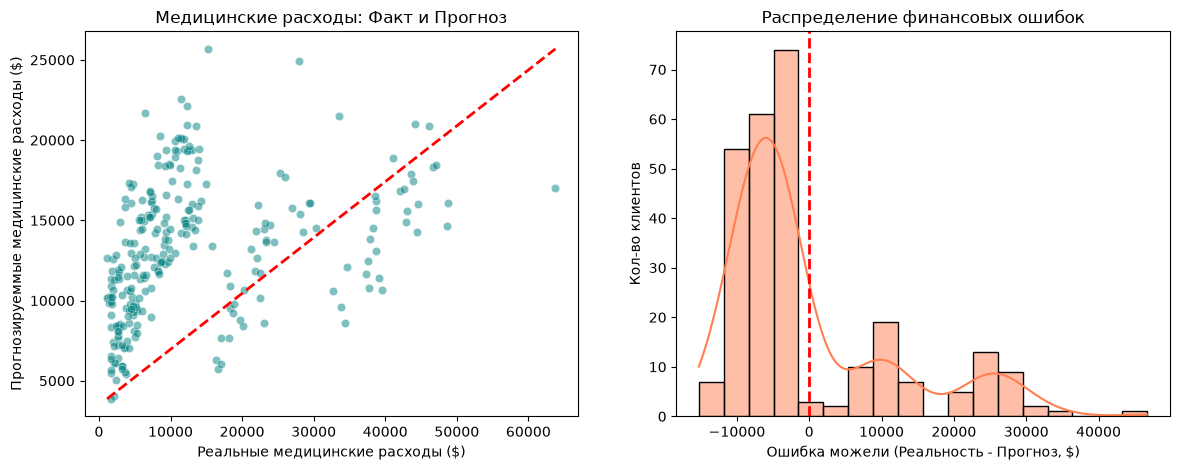

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1,2,figsize=(14,5))

# 1 График: Факт vs Прогноз
sns.scatterplot(x=y_test_r, y=y_pred_r, alpha=0.5, color='teal', ax=axes[0])
axes[0].plot(
    [y_test_r.min(), y_test_r.max()], [y_pred_r.min(), y_pred_r.max()], 'r--', lw=2
)
axes[0].set_title("Медицинские расходы: Факт и Прогноз")
axes[0].set_xlabel("Реальные медицинские расходы ($)")
axes[0].set_ylabel("Прогнозируеммые медицинские расходы ($)")

# 2 График: Распределение ошибок
residuals = y_test_r - y_pred_r
sns.histplot(residuals, kde=True, color='coral', ax=axes[1])
axes[1].axvline(x=0, color='red', linestyle="--", lw=2) # Линия нулевой ошибки
axes[1].set_title("Распределение финансовых ошибок")
axes[1].set_xlabel("Ошибка можели (Реальность - Прогноз, $)")
axes[1].set_ylabel("Кол-во клиентов")
